Libraries

In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from matplotlib import *
import seaborn as sns

import tensorflow as tf
from tensorflow import keras

In [88]:
print(tf.__version__)
np.random.seed(42)

2.21.0


Download Ask and Bid datasets

In [89]:
df_Ask = pd.read_csv('XAGUSD_5 Mins_Ask_2023.01.01_2023.06.30-1.csv')
df_Bid = pd.read_csv('XAGUSD_5 Mins_Bid_2023.01.01_2023.06.30-1.csv')

print(df_Ask.head(3))
print(df_Ask.tail(3))

print(df_Bid.head(3))
print(df_Bid.tail(3))

            Time (UTC)    Open    High     Low   Close  Volume 
0  2023.01.02 23:00:00  24.102  24.125  24.083  24.125    0.351
1  2023.01.02 23:05:00  24.094  24.188  24.094  24.141    1.155
2  2023.01.02 23:10:00  24.143  24.148  24.022  24.027    0.882
                Time (UTC)    Open    High     Low   Close  Volume 
35217  2023.06.30 20:45:00  22.781  22.781  22.776  22.776   0.4212
35218  2023.06.30 20:50:00  22.776  22.797  22.774  22.786   0.6836
35219  2023.06.30 20:55:00  22.786  22.811  22.786  22.811   0.3712
            Time (UTC)    Open    High     Low   Close  Volume 
0  2023.01.02 23:00:00  24.036  24.059  24.017  24.059   0.3480
1  2023.01.02 23:05:00  24.064  24.130  24.064  24.092   1.8458
2  2023.01.02 23:10:00  24.094  24.098  23.972  23.977   0.9030
                Time (UTC)    Open    High     Low   Close  Volume 
35217  2023.06.30 20:45:00  22.751  22.751  22.746  22.746    0.069
35218  2023.06.30 20:50:00  22.746  22.761  22.736  22.756    0.216
35219  2023.

In [90]:
df_Ask.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Time (UTC)  35220 non-null  object 
 1   Open        35220 non-null  float64
 2   High        35220 non-null  float64
 3   Low         35220 non-null  float64
 4   Close       35220 non-null  float64
 5   Volume      35220 non-null  float64
dtypes: float64(5), object(1)
memory usage: 1.6+ MB


In [91]:
df_Bid.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Time (UTC)  35220 non-null  object 
 1   Open        35220 non-null  float64
 2   High        35220 non-null  float64
 3   Low         35220 non-null  float64
 4   Close       35220 non-null  float64
 5   Volume      35220 non-null  float64
dtypes: float64(5), object(1)
memory usage: 1.6+ MB


Merge Ask and Bid Datasets

In [92]:
df_Merged = df_Bid.merge(df_Ask,left_on='Time (UTC)', right_on='Time (UTC)', how='outer')
df_Merged

,Time (UTC),Open_x,High_x,Low_x,Close_x,Volume _x,Open_y,High_y,Low_y,Close_y,Volume _y
0,2023.01.02 23:00:00,24.036,24.059,24.017,24.059,0.3480,24.102,24.125,24.083,24.125,0.3510
1,2023.01.02 23:05:00,24.064,24.130,24.064,24.092,1.8458,24.094,24.188,24.094,24.141,1.1550
2,2023.01.02 23:10:00,24.094,24.098,23.972,23.977,0.9030,24.143,24.148,24.022,24.027,0.8820
3,2023.01.02 23:15:00,23.977,23.980,23.938,23.980,0.8940,24.026,24.028,23.986,24.028,0.8940
4,2023.01.02 23:20:00,23.978,24.024,23.976,24.023,0.8880,24.026,24.073,24.023,24.073,0.9044
...,...,...,...,...,...,...,...,...,...,...,...
35215,2023.06.30 20:35:00,22.752,22.752,22.741,22.746,0.2752,22.782,22.782,22.771,22.776,1.8002
35216,2023.06.30 20:40:00,22.736,22.751,22.736,22.746,0.1410,22.775,22.781,22.775,22.776,0.7568
35217,2023.06.30 20:45:00,22.751,22.751,22.746,22.746,0.0690,22.781,22.781,22.776,22.776,0.4212
35218,2023.06.30 20:50:00,22.746,22.761,22.736,22.756,0.2160,22.776,22.797,22.774,22.786,0.6836


In [93]:
df_Merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Time (UTC)  35220 non-null  object 
 1   Open_x      35220 non-null  float64
 2   High_x      35220 non-null  float64
 3   Low_x       35220 non-null  float64
 4   Close_x     35220 non-null  float64
 5   Volume _x   35220 non-null  float64
 6   Open_y      35220 non-null  float64
 7   High_y      35220 non-null  float64
 8   Low_y       35220 non-null  float64
 9   Close_y     35220 non-null  float64
 10  Volume _y   35220 non-null  float64
dtypes: float64(10), object(1)
memory usage: 3.0+ MB


In [94]:
#Rename columns
df_Merged.columns = ['Local Time','Open_Bid', 'High_Bid','Low_Bid', 'Close_Bid', 'Volume_Bid','Open_Ask', 'High_Ask','Low_Ask','Close_Ask','Volume_Ask']
df_Merged.head(3)

,Local Time,Open_Bid,High_Bid,Low_Bid,Close_Bid,Volume_Bid,Open_Ask,High_Ask,Low_Ask,Close_Ask,Volume_Ask
0,2023.01.02 23:00:00,24.036,24.059,24.017,24.059,0.3480,24.102,24.125,24.083,24.125,0.351
1,2023.01.02 23:05:00,24.064,24.130,24.064,24.092,1.8458,24.094,24.188,24.094,24.141,1.155
2,2023.01.02 23:10:00,24.094,24.098,23.972,23.977,0.9030,24.143,24.148,24.022,24.027,0.882


In [95]:
#Save file
file_obj2 = open('df_Ask_Bid.csv','w')
df_Merged.to_csv('df_Ask_Bid.csv',encoding='utf-8',index=False)
file_obj2.close()

In [96]:
df_Merged = []
df_Merged

[]

In [97]:
df = pd.read_csv('df_Ask_Bid.csv',low_memory=False,sep=',')

In [98]:
#Delta
df['Volume_Delta'] = df['Volume_Ask'] - df['Volume_Bid']
df['Volume_Delta_abs'] = (df['Volume_Ask']- df['Volume_Bid']).abs()

df['Open_Delta'] = df['Open_Ask']-df['Open_Bid']
df['High_Delta'] = df['High_Ask'] - df['High_Bid']
df['Low_Delta'] = df['Low_Ask'] - df['Low_Bid']
df['Close_Delta'] = df['Close_Ask'] - df['Close_Bid']

In [99]:
df.describe()

,Open_Bid,High_Bid,Low_Bid,Close_Bid,Volume_Bid,Open_Ask,High_Ask,Low_Ask,Close_Ask,Volume_Ask,Volume_Delta,Volume_Delta_abs,Open_Delta,High_Delta,Low_Delta,Close_Delta
count,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000
mean,23.357365,23.374611,23.338437,23.357367,8.283187,23.387577,23.404824,23.368703,23.387501,35.095338,26.812151,26.908678,0.030212,0.030212,0.030266,0.030134
std,1.368781,1.368825,1.368926,1.368867,8.976407,1.368779,1.368797,1.368944,1.368861,39.024921,33.422609,33.344942,0.003245,0.003380,0.005014,0.003851
min,19.893000,19.914000,19.888000,19.893000,0.000000,19.923000,19.944000,19.918000,19.923000,0.000000,-48.791200,0.000000,0.011000,0.018000,0.001000,0.012000
25%,22.421750,22.440000,22.400000,22.421000,2.611050,22.452000,22.470000,22.430000,22.451000,9.467675,5.170550,5.237100,0.030000,0.030000,0.030000,0.030000
50%,23.560000,23.576000,23.543000,23.560000,5.331100,23.590000,23.607000,23.573000,23.590000,22.237450,14.907800,14.937300,0.030000,0.030000,0.030000,0.030000
75%,24.122000,24.144000,24.103000,24.122000,10.686275,24.153000,24.174000,24.133000,24.152000,46.639375,36.154925,36.159175,0.030000,0.030000,0.030000,0.030000
max,26.118000,26.123000,26.098000,26.118000,120.651700,26.148000,26.153000,26.128000,26.148000,365.632200,317.585800,317.585800,0.185000,0.222000,0.409000,0.309000


In [100]:
# Ask price = Bid price + Delta, so the Ask Open, High, Low and Close columns are not needed any more
data = df.drop(['Open_Ask', 'High_Ask', 'Low_Ask', 'Close_Ask'],axis=1)
data.shape

(35220, 13)

In [101]:
data.head(3)

,Local Time,Open_Bid,High_Bid,Low_Bid,Close_Bid,Volume_Bid,Volume_Ask,Volume_Delta,Volume_Delta_abs,Open_Delta,High_Delta,Low_Delta,Close_Delta
0,2023.01.02 23:00:00,24.036,24.059,24.017,24.059,0.3480,0.351,0.0030,0.0030,0.066,0.066,0.066,0.066
1,2023.01.02 23:05:00,24.064,24.130,24.064,24.092,1.8458,1.155,-0.6908,0.6908,0.030,0.058,0.030,0.049
2,2023.01.02 23:10:00,24.094,24.098,23.972,23.977,0.9030,0.882,-0.0210,0.0210,0.049,0.050,0.050,0.050


In [102]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Local Time        35220 non-null  object 
 1   Open_Bid          35220 non-null  float64
 2   High_Bid          35220 non-null  float64
 3   Low_Bid           35220 non-null  float64
 4   Close_Bid         35220 non-null  float64
 5   Volume_Bid        35220 non-null  float64
 6   Volume_Ask        35220 non-null  float64
 7   Volume_Delta      35220 non-null  float64
 8   Volume_Delta_abs  35220 non-null  float64
 9   Open_Delta        35220 non-null  float64
 10  High_Delta        35220 non-null  float64
 11  Low_Delta         35220 non-null  float64
 12  Close_Delta       35220 non-null  float64
dtypes: float64(12), object(1)
memory usage: 3.5+ MB


In [103]:
data.describe()

,Open_Bid,High_Bid,Low_Bid,Close_Bid,Volume_Bid,Volume_Ask,Volume_Delta,Volume_Delta_abs,Open_Delta,High_Delta,Low_Delta,Close_Delta
count,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000,35220.000000
mean,23.357365,23.374611,23.338437,23.357367,8.283187,35.095338,26.812151,26.908678,0.030212,0.030212,0.030266,0.030134
std,1.368781,1.368825,1.368926,1.368867,8.976407,39.024921,33.422609,33.344942,0.003245,0.003380,0.005014,0.003851
min,19.893000,19.914000,19.888000,19.893000,0.000000,0.000000,-48.791200,0.000000,0.011000,0.018000,0.001000,0.012000
25%,22.421750,22.440000,22.400000,22.421000,2.611050,9.467675,5.170550,5.237100,0.030000,0.030000,0.030000,0.030000
50%,23.560000,23.576000,23.543000,23.560000,5.331100,22.237450,14.907800,14.937300,0.030000,0.030000,0.030000,0.030000
75%,24.122000,24.144000,24.103000,24.122000,10.686275,46.639375,36.154925,36.159175,0.030000,0.030000,0.030000,0.030000
max,26.118000,26.123000,26.098000,26.118000,120.651700,365.632200,317.585800,317.585800,0.185000,0.222000,0.409000,0.309000


Plot price and Volume charts

<Figure size 1200x500 with 0 Axes>

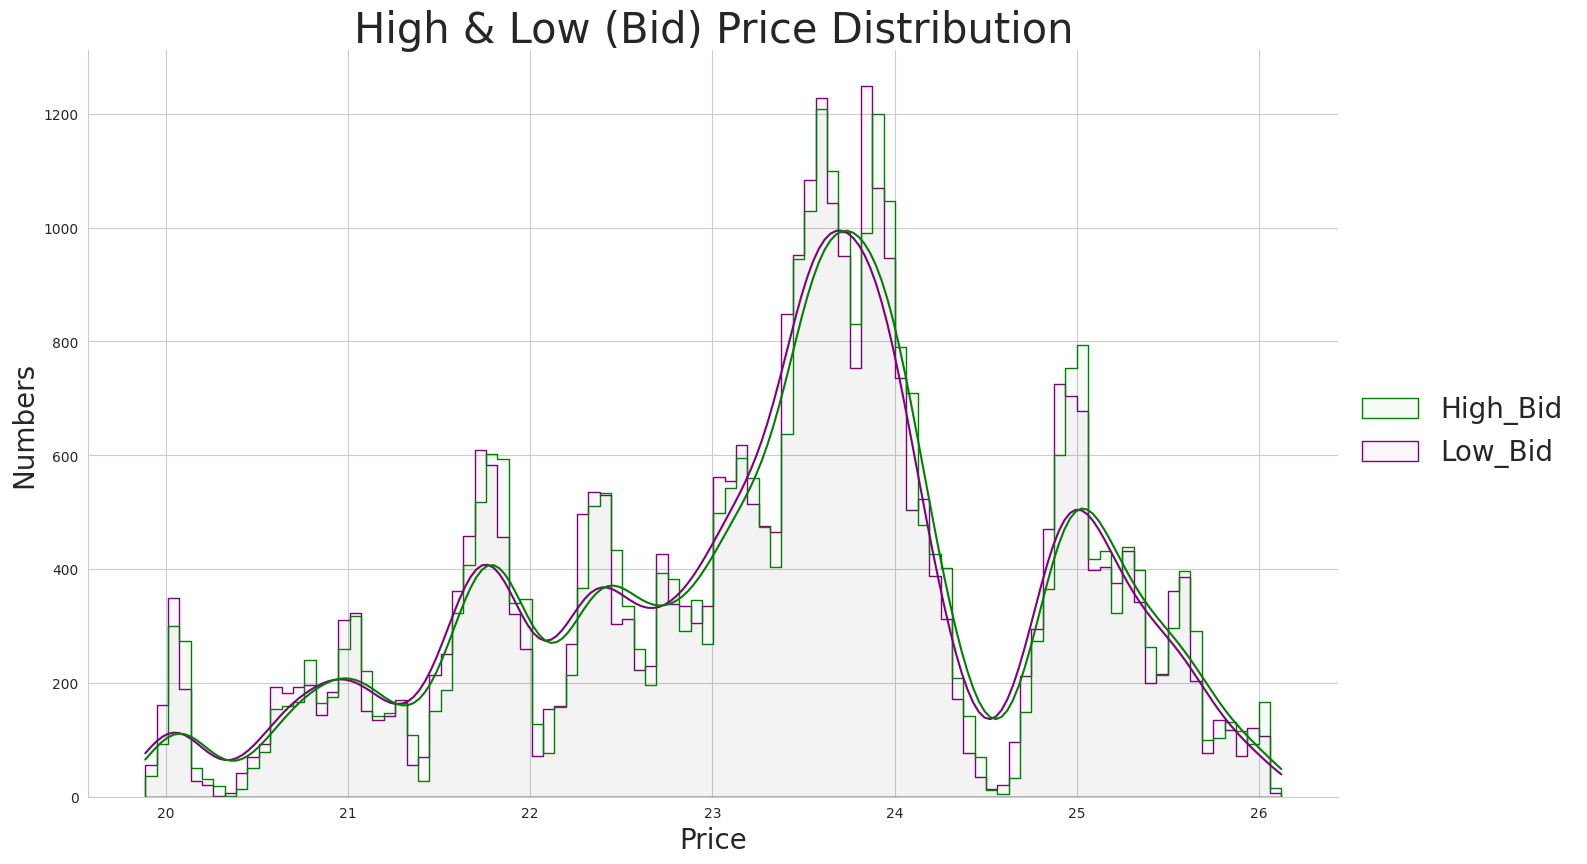

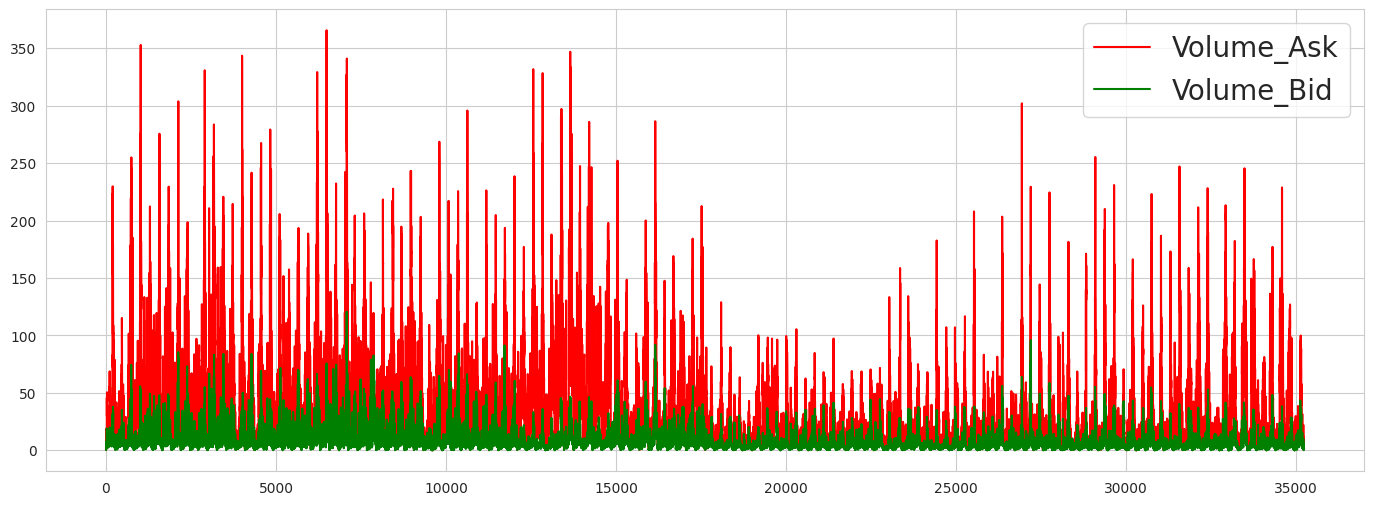

In [104]:
fig = plt.figure(figsize=(12, 5))
plt.rc('axes', titlesize= 30 )
sns.set_style('whitegrid')
sns.set_context(rc={'legend.fontsize': 20.0})

sns.displot(
            data[['High_Bid', 'Low_Bid']],
            height=8,
            aspect=1.7,
            #hue="species",
            kde=True,
            element="step",
            bins=100,
            alpha=0.03,
            palette=['green','purple']

)

plt.title('High & Low (Bid) Price Distribution')
plt.xlabel('Price', size= 20)
#plt.ylabel('count (%)')
plt.ylabel('Numbers', size= 20)
plt.show()



fig = plt.figure(figsize=(17,6)) 
ax1 = fig.add_subplot(111)
line1, = ax1.plot(data['Volume_Ask'],color='red', label='Volume_Ask')
line2, = ax1.plot(data['Volume_Bid'],color='green', label='Volume_Ask')
plt.legend(labels=['Volume_Ask', 'Volume_Bid'], loc='upper right')

plt.show();


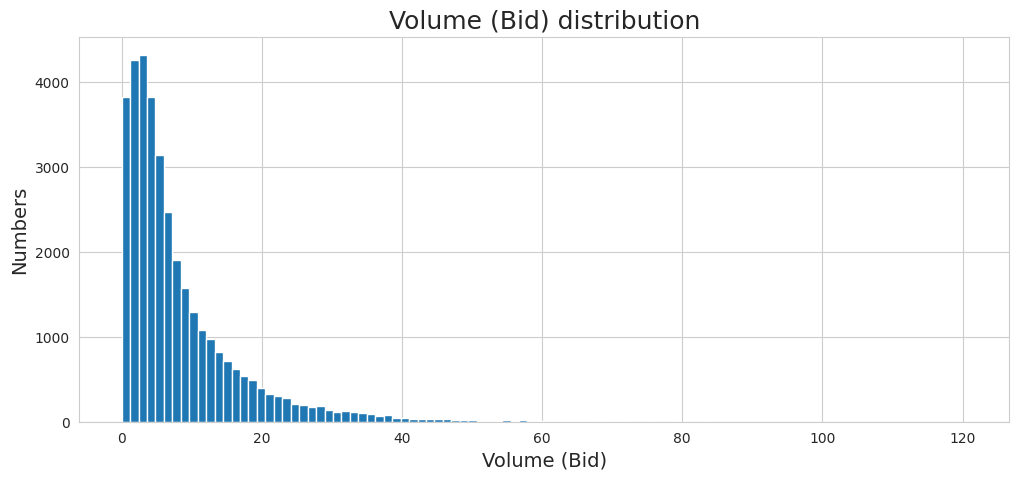

In [105]:
plt.figure(num =1, figsize = (12,5))
plt.hist(data['Volume_Bid'],bins=100)
plt.title('Volume (Bid) distribution', size = 18)
plt.ylabel('Numbers', size=14)
plt.xlabel('Volume (Bid)', size = 14)
plt.show()

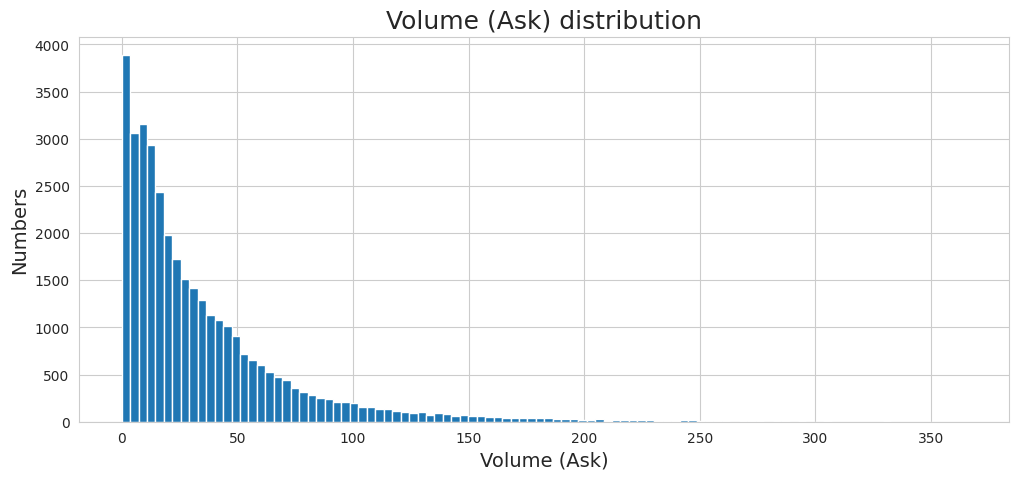

In [106]:
plt.figure(num=1, figsize=(12,5))
plt.hist(data['Volume_Ask'], bins = 100)
plt.title('Volume (Ask) distribution', size=18)
plt.ylabel('Numbers', size= 14)
plt.xlabel('Volume (Ask)', size=14)
plt.show()

Normalise Data

In [107]:
data2 = data.copy()
data2.head(3)

,Local Time,Open_Bid,High_Bid,Low_Bid,Close_Bid,Volume_Bid,Volume_Ask,Volume_Delta,Volume_Delta_abs,Open_Delta,High_Delta,Low_Delta,Close_Delta
0,2023.01.02 23:00:00,24.036,24.059,24.017,24.059,0.3480,0.351,0.0030,0.0030,0.066,0.066,0.066,0.066
1,2023.01.02 23:05:00,24.064,24.130,24.064,24.092,1.8458,1.155,-0.6908,0.6908,0.030,0.058,0.030,0.049
2,2023.01.02 23:10:00,24.094,24.098,23.972,23.977,0.9030,0.882,-0.0210,0.0210,0.049,0.050,0.050,0.050


In [108]:
data2['Y_High_Bid'] = data2['High_Bid']
data2['Y_Low_Ask'] = data2['Low_Bid'] + data2['Low_Delta']

In [109]:
if len(data) > 30000:
    data_length = 30000
else:
    data_length = len(data)
data_length

30000

In [110]:
# 80% of the 30,000 analysed rows (= 24,000) are used to find the Max and Min values for the normalisation.
# The test data must NOT be used here: otherwise the future prices would "leak" into the training
train_size = int(round(data_length*0.8, -3))
train_size

24000

In [111]:
train = data2.iloc[:train_size]
train.shape

(24000, 15)

In [112]:
train.tail(2)

,Local Time,Open_Bid,High_Bid,Low_Bid,Close_Bid,Volume_Bid,Volume_Ask,Volume_Delta,Volume_Delta_abs,Open_Delta,High_Delta,Low_Delta,Close_Delta,Y_High_Bid,Y_Low_Ask
23998,2023.05.05 00:50:00,26.028,26.031,26.007,26.012,1.3227,2.4160,1.0933,1.0933,0.03,0.03,0.03,0.03,26.031,26.037
23999,2023.05.05 00:55:00,26.012,26.021,26.007,26.012,1.2261,3.6974,2.4713,2.4713,0.03,0.03,0.03,0.03,26.021,26.037


In [113]:
# Max price = Max High_Ask = High_Bid + High_Delta
max_price = (train['High_Bid'] + train['High_Delta']).max()
max_price

np.float64(26.111)

In [114]:
# Min price = Min Low_Bid
min_price = train['Low_Bid'].min()
min_price

np.float64(19.888)

In [115]:
max_volume = max(max(train['Volume_Bid']), max(train['Volume_Ask']))
max_volume

365.6322

In [116]:
max_Delta = max(max(train['Open_Delta']), max(train['High_Delta']), max(train['Low_Delta']), max(train['Close_Delta']))
max_Delta

0.30900000000000105

In [117]:
max_Delta = round(max_Delta,3)
max_Delta

0.309

In [118]:
min_Delta = min(min(train['Open_Delta']), min(train['High_Delta']), min(train['Low_Delta']), min(train['Close_Delta']))
min_Delta

0.0009999999999976694

In [119]:
min_Delta = round(min_Delta,3)
min_Delta

0.001

In [120]:
max_volume_Delta = train['Volume_Delta'].max()
max_volume_Delta

np.float64(317.5858)

In [121]:
min_volume_Delta = train['Volume_Delta'].min()
min_volume_Delta

np.float64(-48.7912)

In [122]:
max_volume_Delta_abs = train['Volume_Delta_abs'].max()
max_volume_Delta_abs

np.float64(317.5858)

In [123]:
min_volume_Delta_abs = train['Volume_Delta_abs'].min()
min_volume_Delta_abs

np.float64(0.0)

In [124]:
#Data normalization

# Prices (the inputs and the outputs Y): (x - min_price) / (max_price - min_price)
data2['Open_Bid'] = ( data2['Open_Bid'] - min_price ) / (max_price-min_price)
data2['High_Bid']  = ( data2['High_Bid']  - min_price ) / (max_price-min_price)
data2['Low_Bid']   = ( data2['Low_Bid']   - min_price ) / (max_price-min_price)
data2['Close_Bid'] = ( data2['Close_Bid'] - min_price ) / (max_price-min_price)
data2['Y_High_Bid'] = ( data2['Y_High_Bid'] - min_price ) / (max_price-min_price)
data2['Y_Low_Ask']  = ( data2['Y_Low_Ask']  - min_price ) / (max_price-min_price)

data2['Volume_Delta'] = ( data2['Volume_Delta'] - min_volume_Delta ) / (max_volume_Delta-min_volume_Delta)
data2['Volume_Delta_abs']  = data2['Volume_Delta_abs'] / max_volume_Delta_abs

# Price deltas: inverse normalisation (max - x) / (max - min), because the smallest spread is the most interesting
data2['Open_Delta']  = ( max_Delta - data2['Open_Delta'] )  / (max_Delta-min_Delta)
data2['High_Delta']  = ( max_Delta - data2['High_Delta'] )  / (max_Delta-min_Delta)
data2['Low_Delta']   = ( max_Delta - data2['Low_Delta'] )   / (max_Delta-min_Delta)
data2['Close_Delta'] = ( max_Delta - data2['Close_Delta'] ) / (max_Delta-min_Delta)

In [125]:
data2.head()

,Local Time,Open_Bid,High_Bid,Low_Bid,Close_Bid,Volume_Bid,Volume_Ask,Volume_Delta,Volume_Delta_abs,Open_Delta,High_Delta,Low_Delta,Close_Delta,Y_High_Bid,Y_Low_Ask
0,2023.01.02 23:00:00,0.666560,0.670256,0.663506,0.670256,0.3480,0.3510,0.133180,0.000009,0.788961,0.788961,0.788961,0.788961,0.670256,0.674112
1,2023.01.02 23:05:00,0.671059,0.681665,0.671059,0.675558,1.8458,1.1550,0.131287,0.002175,0.905844,0.814935,0.905844,0.844156,0.681665,0.675880
2,2023.01.02 23:10:00,0.675880,0.676523,0.656275,0.657079,0.9030,0.8820,0.133115,0.000066,0.844156,0.840909,0.840909,0.840909,0.676523,0.664310
3,2023.01.02 23:15:00,0.657079,0.657561,0.650812,0.657561,0.8940,0.8940,0.133172,0.000000,0.844156,0.847403,0.847403,0.847403,0.657561,0.658525
4,2023.01.02 23:20:00,0.657239,0.664631,0.656918,0.664471,0.8880,0.9044,0.133217,0.000052,0.847403,0.844156,0.850649,0.840909,0.664631,0.664471


In [126]:
data2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Local Time        35220 non-null  object 
 1   Open_Bid          35220 non-null  float64
 2   High_Bid          35220 non-null  float64
 3   Low_Bid           35220 non-null  float64
 4   Close_Bid         35220 non-null  float64
 5   Volume_Bid        35220 non-null  float64
 6   Volume_Ask        35220 non-null  float64
 7   Volume_Delta      35220 non-null  float64
 8   Volume_Delta_abs  35220 non-null  float64
 9   Open_Delta        35220 non-null  float64
 10  High_Delta        35220 non-null  float64
 11  Low_Delta         35220 non-null  float64
 12  Close_Delta       35220 non-null  float64
 13  Y_High_Bid        35220 non-null  float64
 14  Y_Low_Ask         35220 non-null  float64
dtypes: float64(14), object(1)
memory usage: 4.0+ MB


In [127]:
file_obj1 = open('Normalised.csv', 'w')
data2.to_csv('Normalised.csv', encoding='utf-8', index=False)
file_obj1.close()

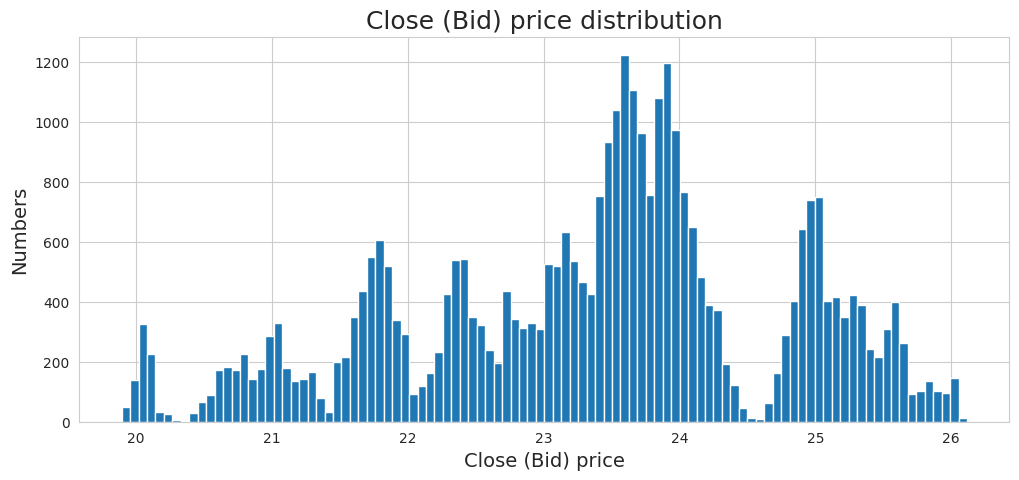

In [128]:
plt.figure(num=1,figsize=(12,5))
plt.hist(data['Close_Bid'],bins=100)
plt.title('Close (Bid) price distribution',size=18)
plt.ylabel('Numbers',size=14)
plt.xlabel('Close (Bid) price',size=14)
plt.show()

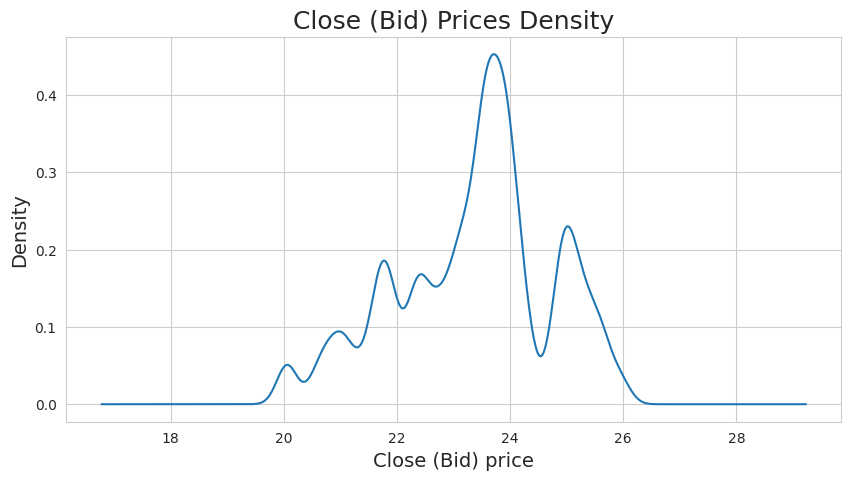

In [129]:
plt.figure(num =1, figsize =(10,5))
data['Close_Bid'].plot.kde()
plt.title('Close (Bid) Prices Density', size = 18)
plt.ylabel('Density', size=14)
plt.xlabel('Close (Bid) price',size= 14)
plt.show()

Shift Min and Max prices

We will predict the Highest (High_Bid) and Lowest (Low_Ask) prices DURING the next 25 minutes.

the time-frame is 5 minutes, so 25 minutes = 5 rows (5 candles x 5 minutes).
(In Week 7 the time-frame was 1 minute, therefore the same 5 rows were only 5 minutes)

To do this in the data output (vector of answers), we shift prices sequentially 1 row up,
and find max and min prices during these 5 rows.
Then we need to delete the 5 last rows since there are no prices for the next 25 minutes.
Therefore, we will create an array of answers "data_ay" with the Highest and Lowest prices shifted sequentially up.

In [130]:
# Inputs: all normalised columns without the answers and without the time text ('Local Time' is a string, not a number)
data_ax = data2.drop(['Local Time','Y_High_Bid','Y_Low_Ask'],axis=1)

In [131]:
data_ax.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35220 entries, 0 to 35219
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Open_Bid          35220 non-null  float64
 1   High_Bid          35220 non-null  float64
 2   Low_Bid           35220 non-null  float64
 3   Close_Bid         35220 non-null  float64
 4   Volume_Bid        35220 non-null  float64
 5   Volume_Ask        35220 non-null  float64
 6   Volume_Delta      35220 non-null  float64
 7   Volume_Delta_abs  35220 non-null  float64
 8   Open_Delta        35220 non-null  float64
 9   High_Delta        35220 non-null  float64
 10  Low_Delta         35220 non-null  float64
 11  Close_Delta       35220 non-null  float64
dtypes: float64(12)
memory usage: 3.2 MB


In [132]:
data_ax.shape

(35220, 12)

In [133]:
data_ay = data2[['Y_High_Bid','Y_Low_Ask']]

In [134]:
data_ay.shape

(35220, 2)

In [135]:
data_ay.head(6)

,Y_High_Bid,Y_Low_Ask
0,0.670256,0.674112
1,0.681665,0.675880
2,0.676523,0.664310
3,0.657561,0.658525
4,0.664631,0.664471
5,0.670577,0.672505


In [136]:
# shift the prices 1 row up: row t now holds the prices of the next candle (t+1)
data_ay = data_ay.shift(-1)

In [137]:
data_ay.tail(10)

,Y_High_Bid,Y_Low_Ask
35210,0.460389,0.462799
35211,0.460389,0.462799
35212,0.459425,0.461192
35213,0.460228,0.462960
35214,0.460228,0.463281
35215,0.460067,0.463924
35216,0.460067,0.464085
35217,0.461674,0.463763
35218,0.462478,0.465692
35219,NaN,NaN


In [138]:
# create new colomns: MIN_Lowest(Low_Ask) and MAX_Highest(High_Bid) prices of DURING NEXT 25 minutes

# Forward-looking window of 5 rows = 5 candles x 5 minutes = 25 minutes
indexer = pd.api.indexers.FixedForwardWindowIndexer(window_size=5)

data_ay['Y_High_Bid_5'] = data_ay['Y_High_Bid'].rolling(window=indexer).max()
data_ay['Y_Low_Ask_5']  = data_ay['Y_Low_Ask'].rolling(window=indexer).min()

In [139]:
data_ay.head(6)


,Y_High_Bid,Y_Low_Ask,Y_High_Bid_5,Y_Low_Ask_5
0,0.681665,0.675880,0.681665,0.658525
1,0.676523,0.664310,0.677005,0.658525
2,0.657561,0.658525,0.677005,0.658525
3,0.664631,0.664471,0.677005,0.664471
4,0.670577,0.672505,0.677005,0.670738
5,0.677005,0.675237,0.677005,0.670738


In [140]:
data_ay.tail(10)

,Y_High_Bid,Y_Low_Ask,Y_High_Bid_5,Y_Low_Ask_5
35210,0.460389,0.462799,0.460389,0.461192
35211,0.460389,0.462799,0.460389,0.461192
35212,0.459425,0.461192,0.460228,0.461192
35213,0.460228,0.462960,0.461674,0.462960
35214,0.460228,0.463281,0.462478,0.463281
35215,0.460067,0.463924,NaN,NaN
35216,0.460067,0.464085,NaN,NaN
35217,0.461674,0.463763,NaN,NaN
35218,0.462478,0.465692,NaN,NaN
35219,NaN,NaN,NaN,NaN


In [141]:
data_ay = data_ay.drop(['Y_High_Bid','Y_Low_Ask'],axis=1)
data_ay.tail(10)

,Y_High_Bid_5,Y_Low_Ask_5
35210,0.460389,0.461192
35211,0.460389,0.461192
35212,0.460228,0.461192
35213,0.461674,0.462960
35214,0.462478,0.463281
35215,NaN,NaN
35216,NaN,NaN
35217,NaN,NaN
35218,NaN,NaN
35219,NaN,NaN


In [142]:
# delete the 5 last rows in data_ay (because we don't have answers for the last 25 minutes)

# Run it ONCE !

for i in range(5):
        data_ay.drop(data_ay.shape[0]-1, axis=0, inplace=True)

In [143]:
# delete the last 5 rows in data_ax (because we don't have answers for the last 25 minutes)

# Run it ONCE !

for i in range(5):
    data_ax.drop(data_ax.shape[0]-1, axis=0, inplace=True)

In [144]:
print(data_ax.shape, data_ay.shape)         # the same number of rows
print(data_ay.isna().sum().sum())           # no NaN left in the answers

(35215, 12) (35215, 2)
0


Separate Inputs and Output matrixes

In [145]:
# Create inputs Numpy

data_a = np.array(data_ax)

with np.printoptions(precision=4):
    print("data_a:")
    print(data_a[:2,:])
    print('\n')
    print(data_a[-2:,:])

print("numpy size: = ", data_a.shape)
print("type: ", data_a.dtype)

data_a:
[[6.6656e-01 6.7026e-01 6.6351e-01 6.7026e-01 3.4800e-01 3.5100e-01
  1.3318e-01 9.4463e-06 7.8896e-01 7.8896e-01 7.8896e-01 7.8896e-01]
 [6.7106e-01 6.8166e-01 6.7106e-01 6.7556e-01 1.8458e+00 1.1550e+00
  1.3129e-01 2.1752e-03 9.0584e-01 8.1494e-01 9.0584e-01 8.4416e-01]]


[[4.5717e-01 4.5942e-01 4.5637e-01 4.5862e-01 1.9267e+00 3.4873e+00
  1.3743e-01 4.9139e-03 9.0584e-01 9.0584e-01 9.0584e-01 9.0584e-01]
 [4.5862e-01 4.6023e-01 4.5814e-01 4.6023e-01 3.6220e-01 1.4552e+00
  1.3616e-01 3.4416e-03 9.0584e-01 9.0584e-01 9.0584e-01 9.0584e-01]]
numpy size: =  (35215, 12)
type:  float64


In [146]:
# Create outputs Numpy

data_y = np.array(data_ay)

print("data_y:")
print(data_y[:3,:])
print('\n')
print(data_y[-3:,:])

print("numpy size: = ", data_y.shape)
print("type: ", data_y.dtype)

data_y:
[[0.68166479 0.65852483]
 [0.67700466 0.65852483]
 [0.67700466 0.65852483]]


[[0.46022819 0.46119235]
 [0.46167443 0.46295999]
 [0.4624779  0.46328138]]
numpy size: =  (35215, 2)
type:  float64


Create a 3D Tensor

In [147]:
from tqdm import tqdm

In [148]:
# We will analyse only part of the dataset since training the neural network with
# an entire dataset would require massive computer power.

# n_small = 30,000 rows (5-minute candles), the same rule as for data_length in Step 4:
# if there are more than 30,000 rows we take 30,000, otherwise all the rows we have
if data_a.shape[0] > 30000:
    n_small = 30000
else:
    n_small = data_a.shape[0]

N=50
L=n_small-N
t= data_a.shape[1]
print('Size of a three-dimensional inputs tensor: ',L,N,t)

Size of a three-dimensional inputs tensor:  29950 50 12


In [149]:
# create imputs zeros 3D tensors with 'float32' or 'float64'

data_b = np.zeros( (L, N, t), dtype= 'float64' )

In [150]:
# create a two-dimensional zeros vector of answers - normalised the High_Bid and Low_Ask prices DURING next 25 minutes

Y = np.zeros((L, 2), dtype= 'float64') # We will predict two prices - normalised High_Bid and normalised Low_Ask

In [151]:
# fill the imputs 3D tansor (data_b)
# and the array of answers Y

#print('L = n - N = ', n-N, L)
print('L = n_small - N = ', n_small-N, L)
#for k in tqdm(range(L-1)):
for k in tqdm(range(L)):
    data_b[k, :, :] = data_a[k:k+N, :]

    Y[k,0] = data_y[k+N-1,0]   # normalised Y_High_Bid - max 25 minutes future price
    Y[k,1] = data_y[k+N-1,1]   # normalised Y_Low_Ask -  min 25 minutes future price

print(k) # index value (for control)

print('data_b:', '\n', data_b)
print("Numpy size:        ", data_b.shape, '\n')

print( Y[:5,:])
print( Y[-10:,:])
print(      "Numpy size:         ", Y.shape)

L = n_small - N =  29950 29950


100%|██████████| 29950/29950 [00:00<00:00, 154723.33it/s]

29949
data_b: 
 [[[0.66655954 0.6702555  0.66350635 ... 0.78896104 0.78896104 0.78896104]
  [0.67105897 0.68166479 0.67105897 ... 0.81493506 0.90584416 0.84415584]
  [0.6758798  0.67652258 0.65627511 ... 0.84090909 0.84090909 0.84090909]
  ...
  [0.69580588 0.70110879 0.69484172 ... 0.90584416 0.90584416 0.90584416]
  [0.69837699 0.70175157 0.69612727 ... 0.91883117 0.90584416 0.90584416]
  [0.69998393 0.71701752 0.69885907 ... 0.90584416 0.90584416 0.90584416]]

 [[0.67105897 0.68166479 0.67105897 ... 0.81493506 0.90584416 0.84415584]
  [0.6758798  0.67652258 0.65627511 ... 0.84090909 0.84090909 0.84090909]
  [0.65707858 0.65756066 0.65081151 ... 0.8474026  0.8474026  0.8474026 ]
  ...
  [0.69837699 0.70175157 0.69612727 ... 0.91883117 0.90584416 0.90584416]
  [0.69998393 0.71701752 0.69885907 ... 0.90584416 0.90584416 0.90584416]
  [0.71621404 0.71701752 0.71042905 ... 0.90584416 0.90584416 0.90584416]]

 [[0.6758798  0.67652258 0.65627511 ... 0.84090909 0.84090909 0.84090909]
  [0.6

In [152]:
# Control of the correctness of filling the array Y
# (should show MAX of the normalised prices High_Bid - during 5 next rows (25 minutes) ahead)


import random

pp = random.randint(50, L-15) # (any number before L-15) - just to look at the middle of data_b
print('random int = ', pp)

print('data_b:', '\t\t','Y:')
print('High_Bid ','\t\t','Y_High_Bid')

for i in range(15):
    print(data_b[pp+i,N-1,1], '\t\t', Y[pp+i,0])

random int =  17931
data_b: 		 Y:
High_Bid  		 Y_High_Bid
0.6355455568053991 		 0.638920134983127
0.6363490278000961 		 0.638920134983127
0.638920134983127 		 0.6379559697894905
0.6379559697894905 		 0.6368311103969143
0.6368311103969143 		 0.6365097219990357
0.633617226418126 		 0.6365097219990357
0.6334565322191864 		 0.6365097219990357
0.6365097219990357 		 0.6384380523863088
0.6355455568053991 		 0.6384380523863088
0.6347420858107022 		 0.6384380523863088
0.6347420858107022 		 0.6447051261449458
0.6347420858107022 		 0.6493652579141889
0.6384380523863088 		 0.6496866463120681
0.6371524987947936 		 0.6496866463120681
0.6363490278000961 		 0.6496866463120681


In [153]:
data = []
data_ax = []
data_ay = []
data_a = []
data_y = []

Train Test split (80% training and validation and 20% testing)

In [154]:
from sklearn.model_selection import train_test_split

In [155]:
# test_size=0.2: the last 20% of the time series are the test data. This matches the 80% (train_size = 24000 rows)
# that was used to find Max and Min in the normalisation (Step 4)
X_train, X_test, y_train, y_test = train_test_split(data_b, Y, test_size=0.2, shuffle = False, stratify = None, random_state=101)

In [156]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(23960, 50, 12)
(23960, 2)
(5990, 50, 12)
(5990, 2)


Create and train neural network for 'MLP'

In [157]:
# The MLP needs one row of numbers as input, but our tensor is [samples, 50, 12].
# The Flatten layer puts the 50 rows x 12 columns of one sample into one row of 600 numbers.
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(50,12)),
    keras.layers.Dense(1024, activation= tf.nn.relu, kernel_initializer = 'normal'),
    keras.layers.Dense(512, activation='relu', kernel_initializer = 'normal'),
    keras.layers.Dense(256, activation= 'relu', kernel_initializer = 'normal'),
    keras.layers.Dense(128, activation= tf.nn.relu, kernel_initializer = 'normal'),
    keras.layers.Dense(2)
])
#50 is depth and 12 is columns

/usr/local/python/3.12.1/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [158]:
print(model.summary())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 600)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1024)           │       615,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,304,706 (4.98 MB)

 Trainable params: 1,304,706 (4.98 MB)

 Non-trainable params: 0 (0.00 B)

None


In [159]:
model.compile(optimizer='adam',loss='mse',metrics=['mae'])

In [ ]:
history = model.fit(X_train, y_train, batch_size =10, epochs=20,validation_split=0.2, verbose = 1)

Epoch 1/20


W0000 00:00:1794874693.063261    4446 cpu_allocator_impl.cc:82] Allocation of 46003200 exceeds 10% of free system memory.


1917/1917 ━━━━━━━━━━━━━━━━━━━━ 25s 12ms/step - loss: 2.7203 - mae: 0.3175 - val_loss: 0.0052 - val_mae: 0.0552
Epoch 2/20
1917/1917 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - loss: 0.0228 - mae: 0.0820 - val_loss: 0.0016 - val_mae: 0.0312
Epoch 3/20
1917/1917 ━━━━━━━━━━━━━━━━━━━━ 31s 12ms/step - loss: 0.0047 - mae: 0.0471 - val_loss: 0.0019 - val_mae: 0.0358
Epoch 4/20
1917/1917 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - loss: 0.0156 - mae: 0.0544 - val_loss: 0.0017 - val_mae: 0.0324
Epoch 5/20
1917/1917 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - loss: 0.0014 - mae: 0.0264 - val_loss: 0.0010 - val_mae: 0.0254
Epoch 6/20


Calculate MSE and MAE on test dataset

In [ ]:
scores = model.evaluate(X_test, y_test, verbose=1)
scores

 71/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0012 - mae: 0.0311

188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 7.0039e-04 - mae: 0.0230


[0.0007003875798545778, 0.022950487211346626]

In [ ]:
print("Mean squared error (mse): %.9f " % (scores[0]))
print("Mean absolute error (mae): %.9f " % (scores[1]))

Mean squared error (mse): 0.000700388 
Mean absolute error (mae): 0.022950487 


Plotting the results graph

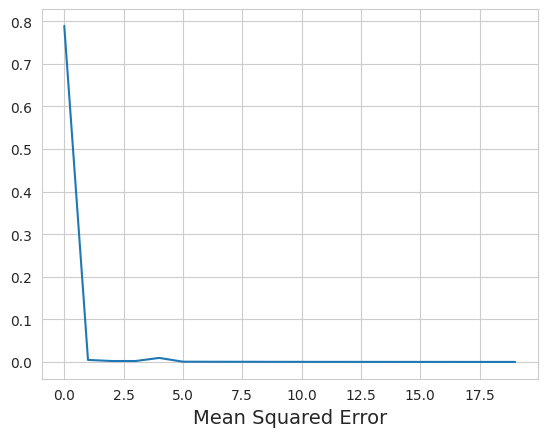

In [ ]:
plt.plot(history.history['loss'])
plt.xlabel('Mean Squared Error',size=14)
plt.show()

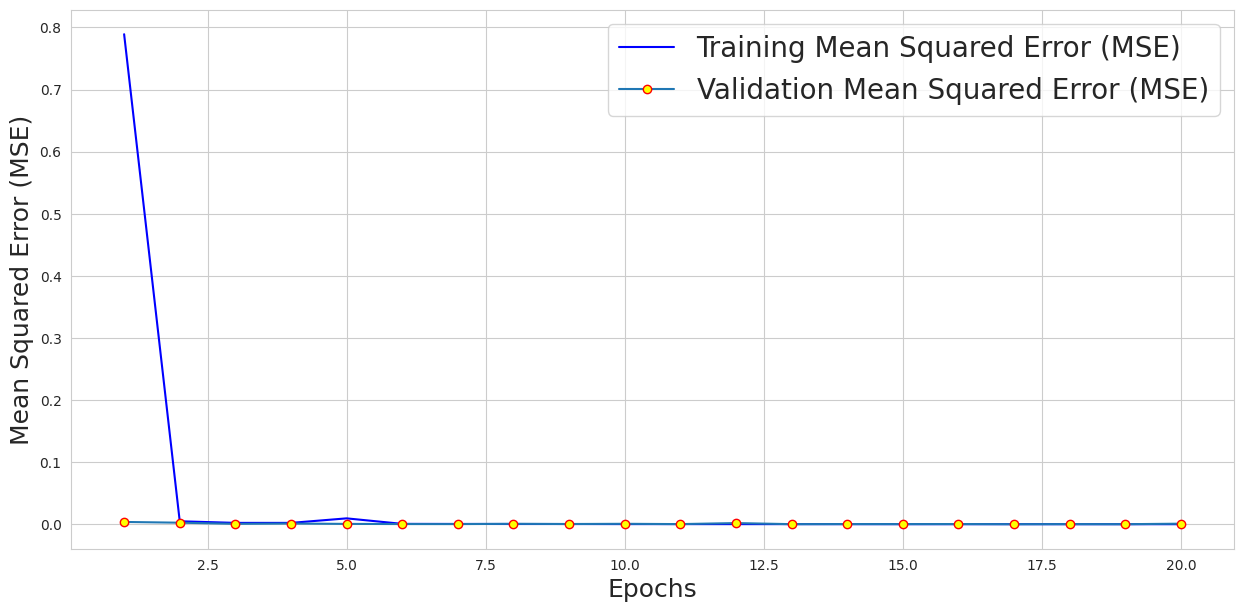

In [ ]:
# More detailed MSE graph

history_dict = history.history

mse_values = history_dict['loss']
val_mse_values = history_dict['val_loss']

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

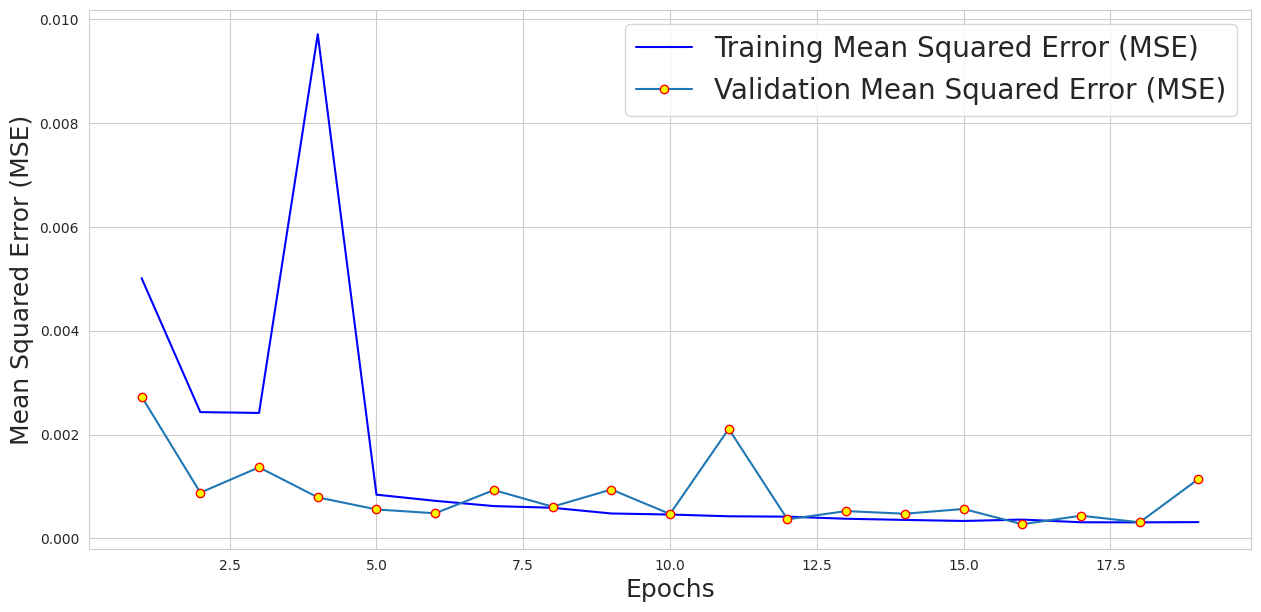

In [ ]:
# deleted the 1st epoch
# to examine in detail the results of the remaining epochs

history_dict = history.history

mse_values = history_dict['loss'][1:]
val_mse_values = history_dict['val_loss'][1:]

epochs = range(1, len(mse_values) + 1)
plt.figure(num=1, figsize=(15,7))
plt.plot(epochs, mse_values, 'b', label='Training Mean Squared Error (MSE)')
plt.plot(epochs, val_mse_values, marker='o', markeredgecolor='red', markerfacecolor='yellow', label='Validation Mean Squared Error (MSE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Squared Error (MSE)', size=18)
plt.legend()
plt.show()

MAE training graphs

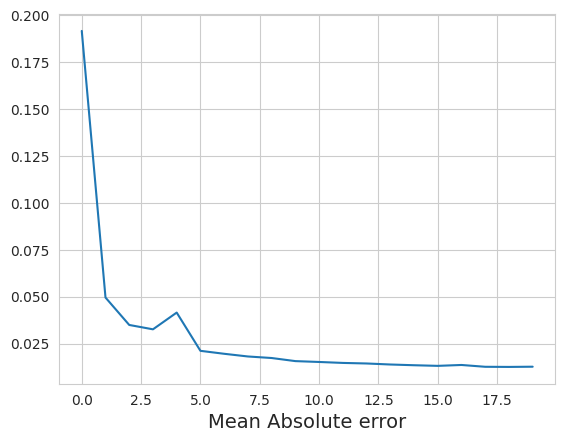

In [ ]:
plt.plot(history.history['mae'])
plt.xlabel('Mean Absolute error', size=14)
plt.show()

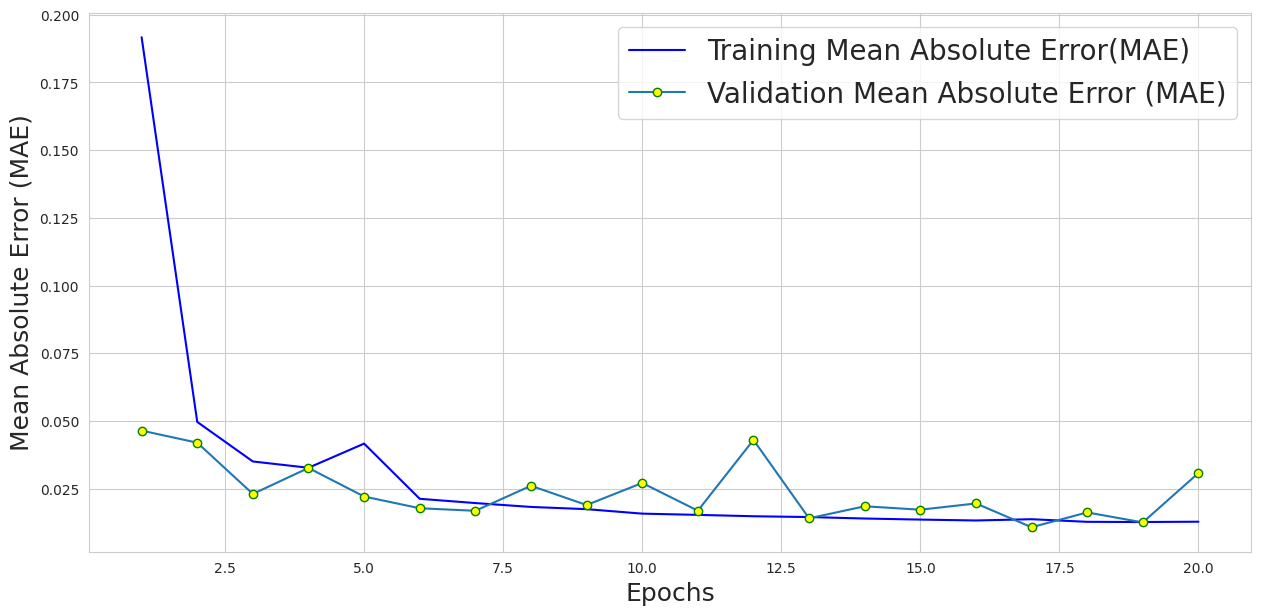

In [ ]:
#MAE Detailed Graph

history_dict = history.history
mae_values = history_dict['mae']
val_mae_values = history_dict['val_mae']

epochs= range(1, len(mae_values)+1)
plt.figure(num=1, figsize = (15,7))
plt.plot(epochs, mae_values, 'b', label = 'Training Mean Absolute Error(MAE)')
plt.plot(epochs, val_mae_values, marker = 'o', markeredgecolor='green', markerfacecolor = 'yellow', label = 'Validation Mean Absolute Error (MAE)')
plt.xlabel('Epochs', size=18)
plt.ylabel('Mean Absolute Error (MAE)', size = 18)
plt.legend()
plt.show()

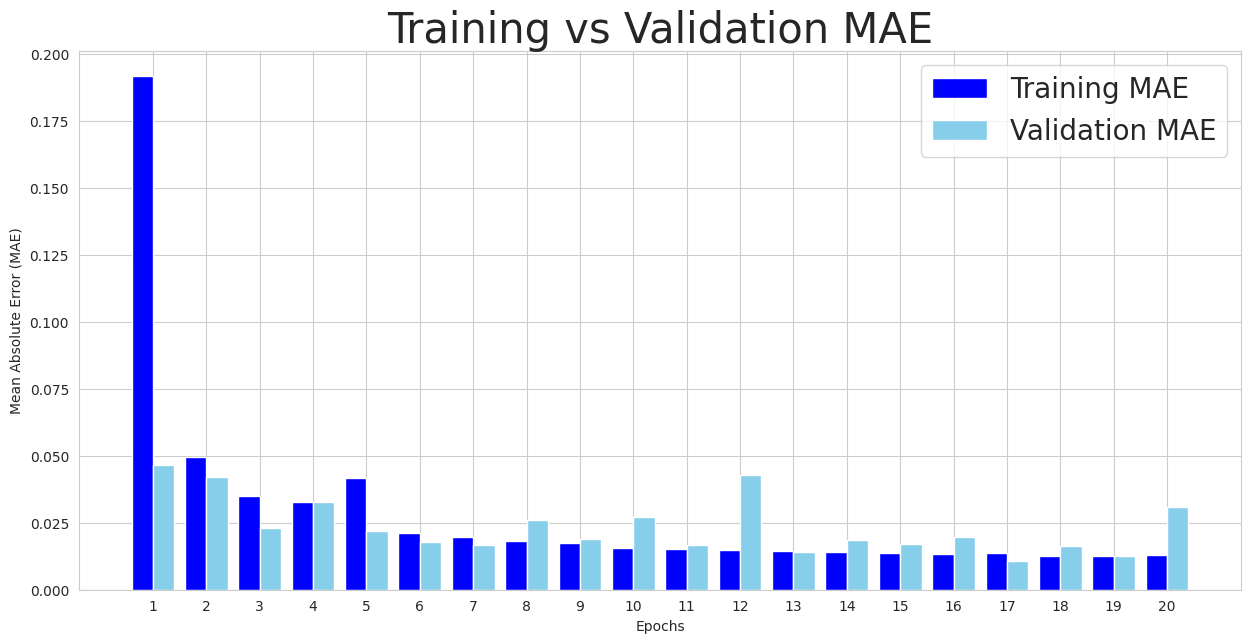

In [ ]:
# Training vs Validation MAE (bar chart)

width = 0.4
plt.figure(figsize=(15, 7))
x = np.arange(len(epochs))
plt.bar(x - width/2, mae_values, width, label='Training MAE', color='blue')
plt.bar(x + width/2, val_mae_values, width, label='Validation MAE', color='yellow')
plt.xlabel('Epochs')
plt.ylabel('Mean Absolute Error (MAE)')
plt.title('Training vs Validation MAE')
plt.xticks(x, epochs)
plt.legend()

plt.show()

Predict 25 mins ahead

In [ ]:
# pred[:,0] - the predicted (normalised) highest High_Bid, pred[:,1] - the predicted (normalised) lowest Low_Ask
pred = model.predict(X_test)
print(pred)

  1/188 ━━━━━━━━━━━━━━━━━━━━ 9s 49ms/step

188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
[[1.0157317  1.0121723 ]
 [1.0179968  1.0144489 ]
 [1.0200375  1.0164999 ]
 ...
 [0.61945385 0.6139018 ]
 [0.6200189  0.6144697 ]
 [0.6202307  0.6146825 ]]


In [ ]:
# Restore the absolute prices ($) from the normalised ones:
# price = normalised * (max_price - min_price) + min_price  (the same min_price and max_price as in the normalisation)

price_delta = max_price - min_price

y_test_price = y_test * price_delta + min_price
pred_price = pred * price_delta + min_price

In [ ]:
import random

n_rec = random.randint(0, X_test.shape[0]-1)

# Run this cell several times and look at the results
for i, name in enumerate(['High_Bid', 'Low_Ask']):
    predicted_price = pred_price[n_rec][i]
    actual_price    = y_test_price[n_rec][i]

    print(name, '\n',
          "Predicted price:", predicted_price, '\n' ,
          "Actual price:", actual_price, '\n',
          "absolut error:", predicted_price - actual_price, '\n',
          "% absolut error:", (predicted_price - actual_price) / actual_price * 100,"%")

High_Bid 
 Predicted price: 25.752279844641684 
 Actual price: 25.536 
 absolut error: 0.21627984464168293 
 % absolut error: 0.846960544492806 %
Low_Ask 
 Predicted price: 25.72783363968134 
 Actual price: 25.543 
 absolut error: 0.18483363968134014 
 % absolut error: 0.7236175847838553 %


price chart

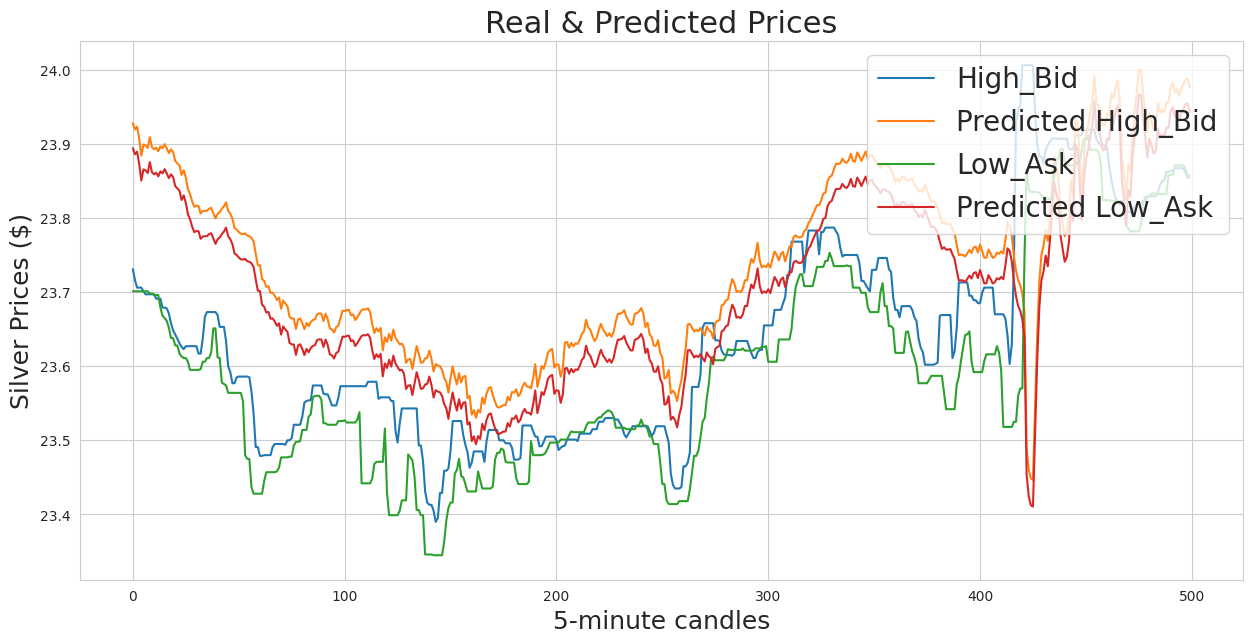

In [ ]:
N1=2500  # The first candle for the chart
LL = 500  # Duration (in 5-minute candles) for the chart
N2=N1+LL  # the last candle for the chart

plt.ion()
fig = plt.figure(figsize=(15,7))

ax1 = fig.add_subplot(111)
line1, = ax1.plot(y_test_price[N1:N2,0], label='High_Bid')
line2, = ax1.plot(pred_price[N1:N2,0], label='Predicted High_Bid')
line3, = ax1.plot(y_test_price[N1:N2,1], label='Low_Ask')
line4, = ax1.plot(pred_price[N1:N2,1], label='Predicted Low_Ask')

plt.title('Real & Predicted Prices', size=22)
plt.ylabel('Silver Prices ($)', size=18)
plt.xlabel('5-minute candles', size=18)
plt.legend(loc='upper right')

plt.show()

Error chart

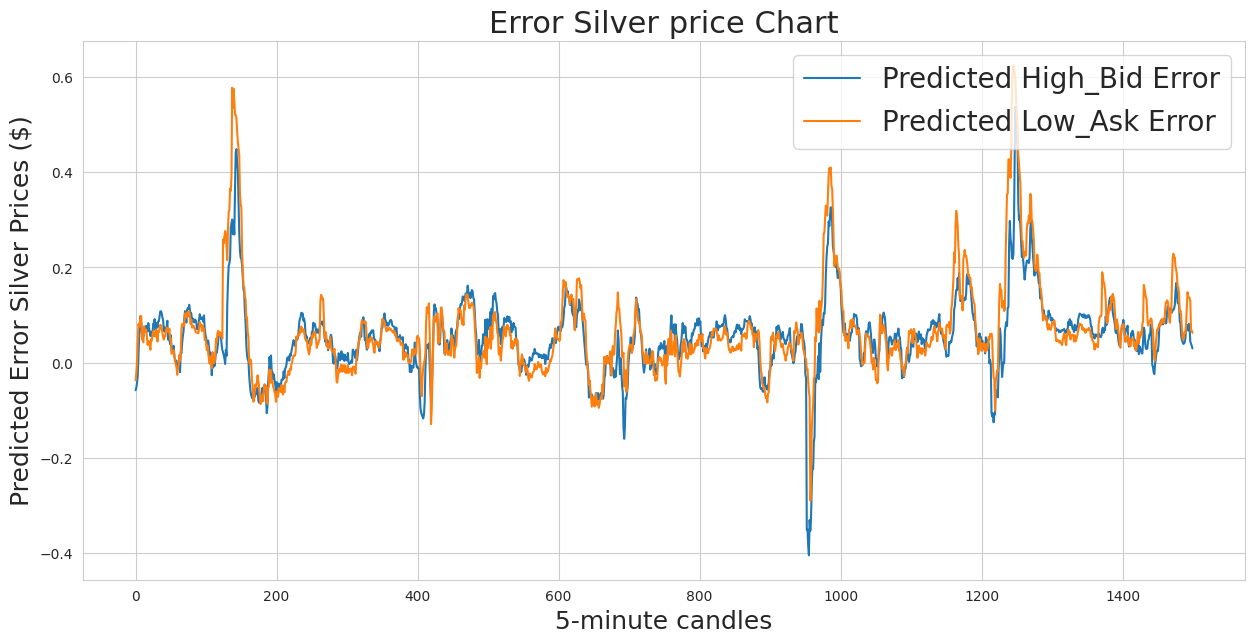

In [ ]:
N1=0  # The first candle for the chart
LL = 1500  # length (in 5-minute candles) for the chart
N2=N1+LL  # the last candle for the chart
# N2 should be < len(pred)

plt.ion()
fig = plt.figure(figsize=(15,7))

ax1 = fig.add_subplot(111)

# in $ (absolute price): the normalised error multiplied by (max_price - min_price)
a = (pred[N1:N2,0] - y_test[N1:N2,0]) * price_delta
b = (pred[N1:N2,1] - y_test[N1:N2,1]) * price_delta

line1, = ax1.plot(a, label='Predicted High_Bid Error', coloer='green')
line2, = ax1.plot(b, label='Predicted Low_Ask Error')

plt.title('Error Silver price Chart', size=22)
plt.ylabel('Predicted Error Silver Prices ($)', size=18)
plt.xlabel('5-minute candles', size=18)
plt.legend(loc='upper right')

plt.show()